# **Практическая работа №11. Анализ и сегментация клиентов с помощью алгоритмов кластеризации**

### **Цель работы:**

Разработать систему сегментации клиентов для розничной компании с использованием алгоритмов кластеризации. Это позволит компании лучше понимать своих клиентов, персонализировать маркетинговые кампании и оптимизировать бизнес-процессы.

### **Введение:**

Розничные компании сталкиваются с большим объемом данных о своих клиентах, включая историю покупок, демографическую информацию и поведенческие характеристики. Однако без должного анализа эти данные остаются неиспользованными. Сегментация клиентов позволяет выделить группы с общими характеристиками, чтобы более эффективно таргетировать предложения и улучшить удовлетворенность клиентов.



### **Задачи:**

1. **Сбор и анализ данных о клиентах.**
2. **Предобработка и подготовка данных для моделирования.**
3. **Применение различных алгоритмов кластеризации для сегментации клиентов.**
4. **Оценка качества кластеризации с использованием внутренних и внешних метрик.**
5. **Интерпретация и визуализация результатов.**
6. **Формирование рекомендаций для бизнес-стратегии компании на основе полученных сегментов.**



### **Пошаговое описание рабочего процесса (пайплайна):**

#### **Шаг 1: Сбор и анализ данных**

**1.1. Выбор набора данных:**

- Используйте датасет "Online Retail II" из [UCI Machine Learning Repository](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci) или [другой открытый набор данных](https://archive.ics.uci.edu/datasets?Task=Clustering&skip=0&take=10&sort=desc&orderBy=NumHits&search=&Area=Business), содержащий информацию о транзакциях клиентов.
- Данные должны включать:
  - Идентификаторы клиентов.
  - Информацию о покупках (товары, количество, стоимость).
  - Дату и время транзакций.
  - Демографические данные (если доступны): возраст, пол, локация и т.д.

**1.2. Первичный анализ данных (EDA):**

- Изучите структуру данных и их распределение.
- Определите основные характеристики данных:
  - Общий объем продаж.
  - Частота покупок по клиентам.
  - Распределение выручки по товарам.
- Выявите тенденции и аномалии.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail.csv")

print("Размер датасета:", df.shape)
print(df.info())
print(df.isnull().sum())

df.head()

Размер датасета: (1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB
None
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


#### **Шаг 2: Предобработка данных**

**2.1. Работа с пропущенными значениями:**

- Проанализируйте наличие пропущенных данных.
- Решите, как справиться с ними:
  - Удаление строк/столбцов с пропущенными значениями.
  - Заполнение пропущенных значений средним, медианой или наиболее частым значением.

**2.2. Обработка выбросов:**

- Выявите выбросы в данных (например, аномально большие заказы).
- Решите, следует ли их удалить или обработать иным образом.

**2.3. Создание новых признаков:**

- Рассчитайте Recency, Frequency, Monetary Value (RFM-анализ):
  - **Recency (давность):** Время с момента последней покупки.
  - **Frequency (частота):** Количество покупок за определенный период.
  - **Monetary (сумма):** Общая сумма покупок.
- Создайте дополнительные признаки, такие как средний чек, предпочтительные категории товаров и т.д.

**2.4. Нормализация и масштабирование:**

- Примените стандартизацию или нормализацию к числовым признакам для приведения их к единому масштабу.
- Объясните выбор метода масштабирования.

In [2]:
df = df.copy()

# Удаляем строки без Customer ID
df = df.dropna(subset=["Customer ID"])

# Убираем возвраты и некорректные значения
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["Price"]

# RFM-признаки
a = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (a - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

# Убираем сильные выбросы
for col in ["Recency", "Frequency", "Monetary"]:
    q1 = rfm[col].quantile(0.01)
    q2 = rfm[col].quantile(0.99)
    rfm = rfm[(rfm[col] >= q1) & (rfm[col] <= q2)]

print("Количество клиентов после предобработки:", len(rfm))
rfm.head()

Количество клиентов после предобработки: 5647


,Customer ID,Recency,Frequency,Monetary
1,12347.0,2,8,5633.32
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93


#### **Шаг 3: Применение алгоритмов кластеризации**

**3.1. Выбор алгоритмов:**

- **K-средних (K-Means):** Для разбиения данных на k кластеров на основе эврестического подхода.
- **Иерархическая кластеризация:** Для выявления вложенной структуры кластеров.
- **DBSCAN и OPTICS:** Для обнаружения кластеров произвольной формы и выявления выбросов.

**3.2. Определение оптимального количества кластеров:**

- Для K-Means и иерархической кластеризации используйте:
  - **Метод локтя (Elbow Method):** Постройте график зависимости суммы квадратов внутрикластерных расстояний от числа кластеров.
  - **Коэффициент силуэта:** Рассчитайте для различных значений k и выберите оптимальное.

**3.3. Применение алгоритмов:**

- Запустите каждый алгоритм на подготовленных данных.
- Сохраняйте результаты кластеризации для последующего анализа.

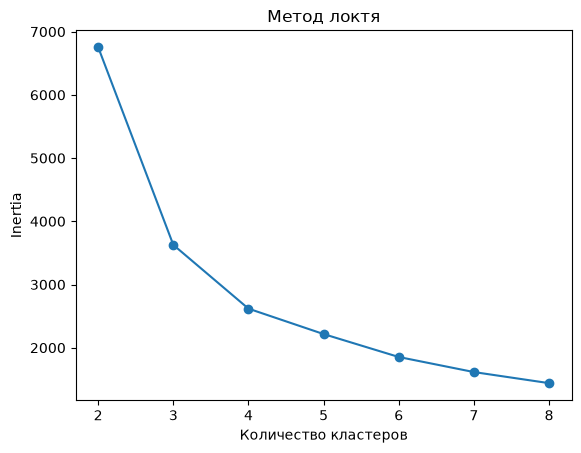

      KMeans  Hierarchical  DBSCAN  OPTICS
2214       2             3       0      -1
2724       0             2       0      -1
1427       2             1       0      -1
3897       0             2       0      -1
1031       2             1       0      -1


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS

features = ["Recency", "Frequency", "Monetary"]

# Для ускорения используем максимум 4000 клиентов
data_model = rfm.sample(min(4000, len(rfm))).copy()

scaler = StandardScaler()
X = scaler.fit_transform(data_model[features])

# K-Means
inertia = []

for k in range(2, 9):
    a = KMeans(n_clusters=k, n_init=10)
    a.fit(X)
    inertia.append(a.inertia_)

plt.plot(range(2, 9), inertia, marker="o")
plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.title("Метод локтя")
plt.show()

kmeans = KMeans(n_clusters=4, n_init=10)
data_model["KMeans"] = kmeans.fit_predict(X)

# Иерархическая кластеризация
hier = AgglomerativeClustering(n_clusters=4)
data_model["Hierarchical"] = hier.fit_predict(X)

# DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=8)
data_model["DBSCAN"] = dbscan.fit_predict(X)

# OPTICS
optics = OPTICS(min_samples=8, xi=0.05)
data_model["OPTICS"] = optics.fit_predict(X)

print(data_model[["KMeans", "Hierarchical", "DBSCAN", "OPTICS"]].head())

#### **Шаг 4: Оценка качества кластеризации**

**4.1. Внутренние метрики:**

- **Коэффициент силуэта:** Оцените, насколько хорошо объекты расположены внутри кластеров.
- **Индекс Дэвиса-Болдина:** Оцените уровень разделимости кластеров.
- **Индекс Калинского-Харабаза:** Оцените соотношение межкластерной дисперсии к внутрикластерной.

**4.2. Внешние метрики (если доступны истинные метки):**

- **Adjusted Rand Index (ARI):** Сравните полученные кластеры с известными категориями клиентов.
- **Normalized Mutual Information (NMI):** Измерьте общую информацию между распределениями.

**4.3. Сравнение алгоритмов:**

- Составьте таблицу со значениями метрик для каждого алгоритма.
- Определите, какой алгоритм показал наилучшие результаты и почему.

In [4]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

def evaluate_clustering(name, labels):
    # Шум DBSCAN/OPTICS (-1) не учитываем при расчете
    mask = labels != -1
    labels2 = labels[mask]
    X2 = X[mask]

    if len(np.unique(labels2)) < 2:
        return [name, None, None, None, len(np.unique(labels))]

    return [
        name,
        silhouette_score(X2, labels2),
        davies_bouldin_score(X2, labels2),
        calinski_harabasz_score(X2, labels2),
        len(np.unique(labels))
    ]

results = []

results.append(evaluate_clustering("KMeans", data_model["KMeans"].values))
results.append(evaluate_clustering("Hierarchical", data_model["Hierarchical"].values))
results.append(evaluate_clustering("DBSCAN", data_model["DBSCAN"].values))
results.append(evaluate_clustering("OPTICS", data_model["OPTICS"].values))

metrics = pd.DataFrame(
    results,
    columns=[
        "Модель",
        "Silhouette",
        "Davies-Bouldin",
        "Calinski-Harabasz",
        "Количество кластеров"
    ]
)

display(metrics)

print("Внешние метрики не рассчитываются, так как в датасете нет истинных меток кластеров.")

,Модель,Silhouette,Davies-Bouldin,Calinski-Harabasz,Количество кластеров
0,KMeans,0.495112,0.751260,4773.106528,4
1,Hierarchical,0.435186,0.833835,3945.018006,4
2,DBSCAN,0.710992,0.251909,255.822228,3
3,OPTICS,0.555112,0.598970,4332.114189,96


Внешние метрики не рассчитываются, так как в датасете нет истинных меток кластеров.


#### **Шаг 5: Интерпретация и визуализация результатов**

**5.1. Визуализация кластеров:**

- **Снижение размерности:** Примените PCA или t-SNE или UMAP для отображения данных в 2D или 3D пространстве.
- **Постройте графики:**
  - Рассеивания с цветовой кодировкой кластеров.
  - Дендрограммы для иерархической кластеризации.
- **Визуализация признаков:**
  - Постройте боксплоты, гистограммы или тепловые карты для сравнения признаков между кластерами.

**5.2. Описание сегментов:**

- Для каждого кластера опишите характерные черты:
  - Средние значения признаков.
  - Поведенческие особенности (например, частота покупок, средний чек).
  - Демографические характеристики (если доступны).
- Присвойте сегментам осмысленные названия (например, "Лояльные клиенты", "Покупатели со сниженной активностью", "Большие транзакции").

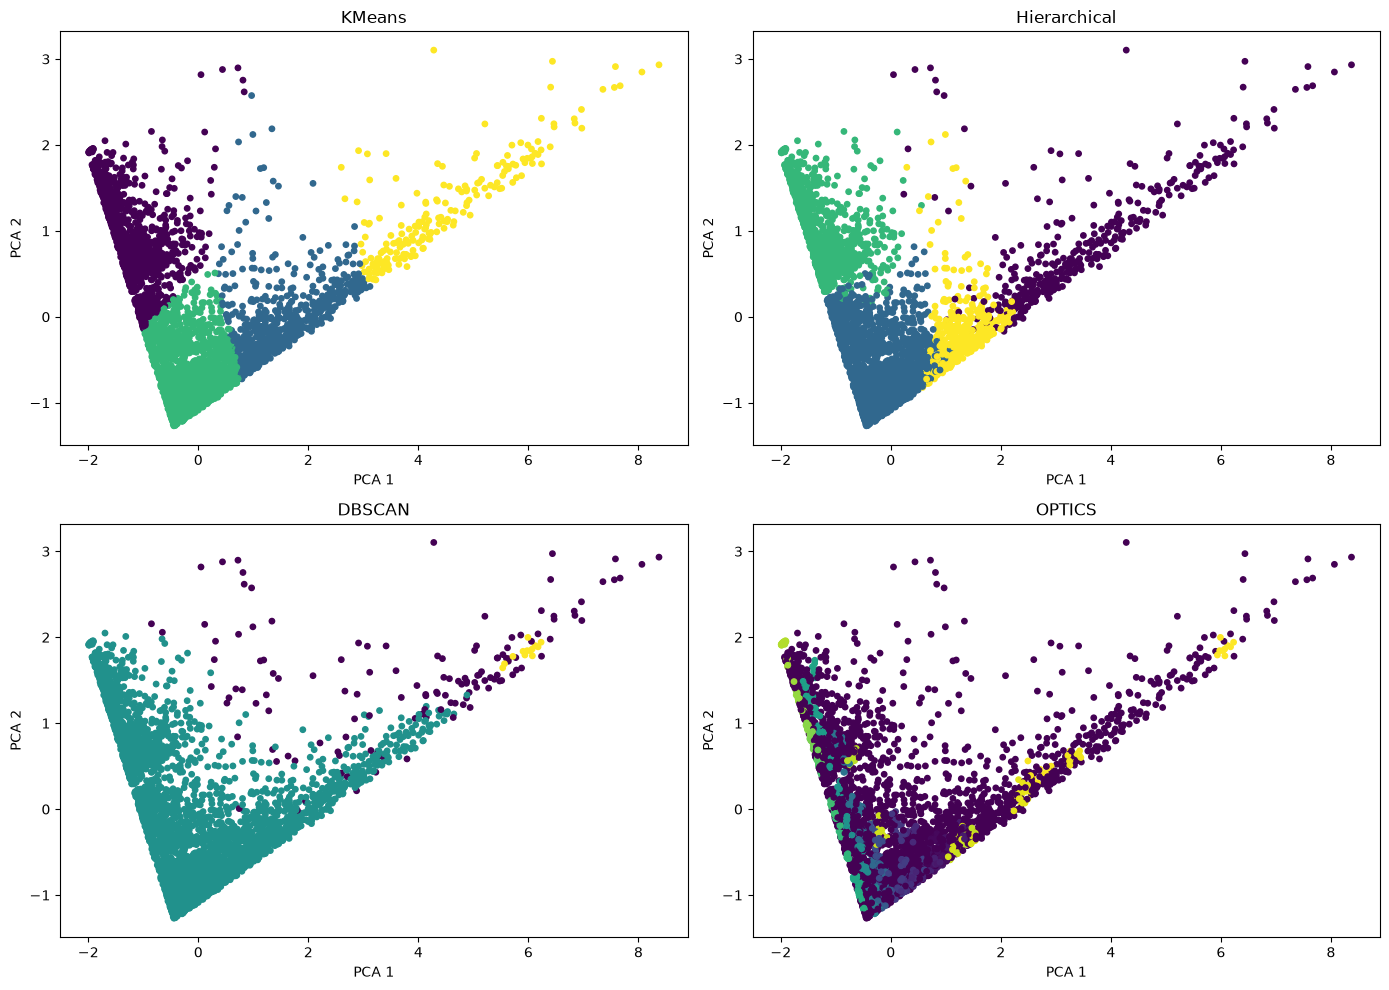

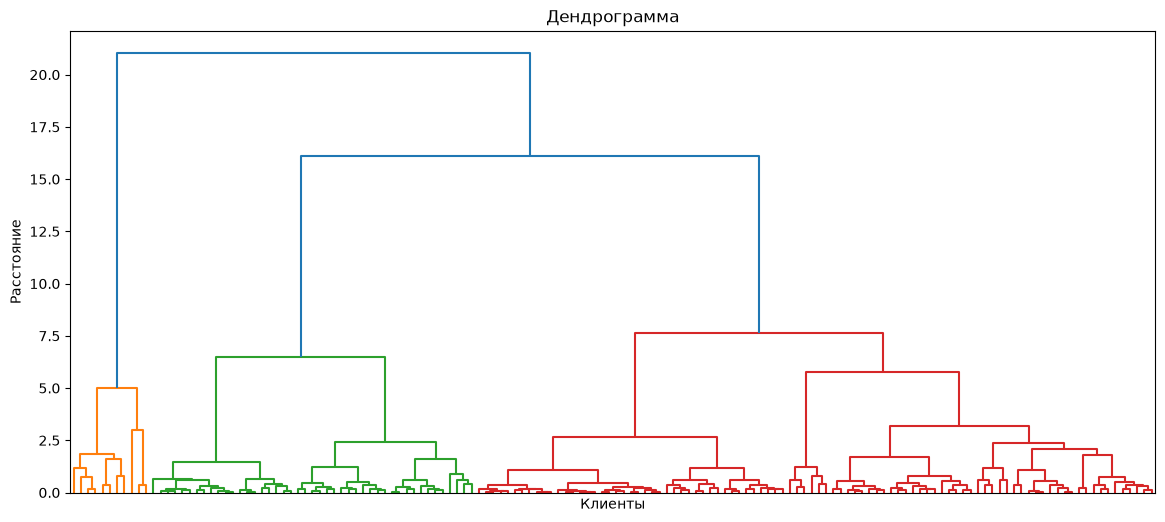

,Recency,Frequency,Monetary,Customers
KMeans,,,,
0,460.68,2.03,658.27,1290
1,56.39,11.03,4226.78,662
2,81.47,3.28,983.11,1856
3,33.46,24.28,10997.05,192


In [5]:
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# PCA для визуализации
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

algorithms = ["KMeans", "Hierarchical", "DBSCAN", "OPTICS"]

for i, name in enumerate(algorithms):
    ax = axes.flat[i]

    ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=data_model[name],
        s=15
    )

    ax.set_title(name)
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")

plt.tight_layout()
plt.show()

# Дендрограмма на небольшой выборке клиентов
a = X[:150]
linked = linkage(a, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(linked, no_labels=True)
plt.title("Дендрограмма")
plt.xlabel("Клиенты")
plt.ylabel("Расстояние")
plt.show()

# Профили сегментов K-Means
profile = data_model.groupby("KMeans")[features].mean().round(2)
profile["Customers"] = data_model["KMeans"].value_counts()

display(profile)

#### **Шаг 6: Формирование бизнес-рекомендаций**

**6.1. Анализ потребностей каждого сегмента:**

- Определите потребности и предпочтения клиентов в каждом сегменте.
- Выявите возможности для увеличения продаж и улучшения сервиса.

**6.2. Разработка стратегий для каждого сегмента:**

- **Маркетинговые кампании:**
  - Персонализированные предложения.
  - Программы лояльности для удержания ценных клиентов.
- **Оптимизация продуктов:**
  - Расширение ассортимента для популярных сегментов.
  - Фокус на продуктах, интересных конкретным сегментам.

**6.3. Оценка потенциального влияния:**

- Оцените, как предложенные стратегии могут повысить выручку, удовлетворенность клиентов и другие ключевые показатели.

**Ответ**:

| Что получим | Как это работает |
|-------------|---------------|
| **Клиенты чувствуют заботу** | Персонализация и удобство вызывают больше доверия, что приводит к большему числу повторных покупок |
| **Меньше «потерянных» клиентов** | Своевременные напоминания и бонусы заставляют людей возвращаются, а не уходить к конкурентам |
| **Растёт ценность каждого клиента** | Программы лояльности, в которых находятся клиенты, позволяют им покупать чаще и дороже |
| **Сарафанное радио** | Довольные клиенты (особенно из кластера 0 и 2) рекомендуют нас друзьям, откуда появляются новые клиенты без затрат на рекламу |


#### **Шаг 7: Документирование и презентация результатов**

**7.1. Подготовка отчета:**

- **Введение:**
  - Описание цели работы и её значимости для бизнеса.
- **Методология:**
  - Подробное описание проведенных шагов.
- **Результаты:**
  - Представление метрик оценки и визуализаций.
  - Описание сегментов клиентов.
- **Обсуждение:**
  - Анализ полученных результатов.
  - Сравнение алгоритмов и обоснование выбора.
- **Рекомендации:**
  - Предложения по внедрению результатов в бизнес-процессы.
- **Заключение:**
  - Выводы о проделанной работе и её значимости.

**7.2. Презентация:**

- Подготовьте слайды для представления ключевых моментов работы.
- Используйте визуализации для иллюстрации результатов.




# **Отчет**

- **Введение:**
  - Розничные компании сталкиваются с большим объемом данных о своих клиентах, включая историю покупок, демографическую информацию и поведенческие характеристики. Однако без должного анализа эти данные остаются неиспользованными. Сегментация клиентов позволяет выделить группы с общими характеристиками, чтобы более эффективно таргетировать предложения и улучшить удовлетворенность клиентов.
  - Цель работы: Разработать систему сегментации клиентов для розничной компании с использованием алгоритмов кластеризации. Это позволит компании лучше понимать своих клиентов, персонализировать маркетинговые кампании и оптимизировать бизнес-процессы.
- **Методология:**
  1. **Сбор и анализ данных о клиентах** – загрузка датасета “Online Retail II”
  2. **Предобработка и подготовка данных для моделирования** – предобработка данных с помощью pandas
  3. **Применение различных алгоритмов кластеризации для сегментации клиентов** – применение из scikit-learn алгоритмов K-Means, DBSCAN, иерархической кластеризации
  4. **Оценка качества кластеризации с использованием внутренних метрик** – оценка с помощью Коэффициента силуэта, индекса Дэвиса-Болдина, индекса Калинского-Харабаза (метрики из scikit-learn)
  5. **Интерпретация и визуализация результатов** – визуализация полученных кластеров с помощью matplotlib, plotly.express, seaborn; выделение полученных кластеров
  6. **Формирование рекомендаций для бизнес-стратегии компании на основе полученных сегментов** – создание рекомендаций на основе полученных результатов, разработка стратегий для каждого сегмента, анализ потребностей каждого из них
- **Результаты:**
  - см. пункт 4.3 (оценки алгоритмов при 3/4/5 кластерах и DBSCAN при разных значениях eps) и 5.1 (визуализация результатов)
  - Наилучшие результаты наблюдались при k=3 (K-Means), были выделены кластеры лояльных; редких/новых; частых клиентов
- **Обсуждение:**
  - Наилучшие результаты как и в визуализации, так и по метрикам, показал алгоритм K-Means.
  - DBSCAN хоть и закинул всё под один кластер (при k=3), но помог выявить вероятные шумы в данных.
  - Иерархическая кластеризация практически схожа с K-Means, но уступает в эффективности по полученным результатам
- **Рекомендации:**
  | Сегмент | Потребности | Возможности| Оптимизация |
|---------|-------------|--------|---------------------|
| **Кластер 0** (Частые) | Быстрый доступ к товарам повседневного спроса<br>Удобство оформления, оперативная доставка<br>Небольшие, но регулярные покупки: важны акции, подписки, кэшбэк | Стимулировать переход в «лояльных» клиентов через программу накопительных баллов.<br>Реферальные программы (приведи друга - бонусы обоим).| Бандлы «часто покупают вместе»<br>Мини-форматы товаров по сниженной цене<br>Упрощённый повтор заказа в 1 клик|
| **Кластер 1** (Редкие/новые) | Знакомство с брендом, низкий порог входа, доверие к качеству<br>Мотивация на повторную покупку (персональные скидки, приветственные бонусы)| Уведомления через email/push-уведомления с персональными предложениями| Стартовые наборы для знакомства с ассортиментом<br>Персональные рекомендации на основе первого заказа|
| **Кластер 2** (Лояльные) | Признание ценности, эксклюзивный сервис, ранний доступ к новинкам<br>Персонализация: индивидуальные подборки, персональный менеджер| Удержание через VIP-программы, приглашения на закрытые распродажи| Премиум-линейки товаров, лимитированные коллекции<br>Индивидуальные подборки на основе истории покупок |
- **Заключение:**
  -  Проделанная работа позволила использовать данные, которые оставались у компаний незатронутыми, в целях улучшения эффективности продаж и повышения удовлетворенности клиентов. Можно и дальше продолжить поиск кластеров, однако данного числа уже достаточно для небольшого прироста эффективности

